# Classifying Fashion-MNIST Images with Classical ML and Dimensionality Reduction

**Goal:** Find out how well classical machine learning models can separate two clothing classes, trousers and dresses, from raw pixel data, and whether reducing the number of features helps.

**Data:** 2,400 grayscale images (28×28 pixels, 784 features) from the [Fashion-MNIST dataset](https://www.kaggle.com/datasets/zalando-research/fashionmnist) by Zalando Research. The classes are roughly balanced (1,238 trousers, 1,162 dresses).

**Approach:**
1. Compare SVM, naive Bayes (Gaussian, multinomial, Bernoulli) and linear discriminant analysis (LDA).
2. Test four preprocessing methods and tune each model's hyperparameters on a validation set.
3. Combine every model with PCA and locally linear embedding (LLE).

**Result:** An SVM with min-max scaling and PCA (11 components) gave the best validation accuracy (98.96%) and reached **96.88% accuracy on the held-out test set**.

**Tools:** Python, scikit-learn, pandas, NumPy, Matplotlib

### Contents
1. Data
2. Exploratory analysis
3. Evaluation setup
4. Baseline models
5. Effect of preprocessing
6. Hyperparameter tuning
7. Dimensionality reduction (PCA, LLE)
8. Results summary
9. Final model on the test set
10. Conclusions and limitations
11. Predictions for unlabelled data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import LocallyLinearEmbedding
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix)
from sklearn.model_selection import ParameterGrid, train_test_split
from sklearn.naive_bayes import BernoulliNB, GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Binarizer, MinMaxScaler, RobustScaler, StandardScaler
from sklearn.svm import SVC

import sklearn

%matplotlib inline
print("scikit-learn", sklearn.__version__)

RANDOM_SEED = 534134
DATA_DIR = Path("data")
CLASS_NAMES = ["Trousers", "Dress"]   # label 0, label 1

scikit-learn 1.9.1


## 1. Data

`train.csv` holds 2,400 labelled images. Each row is one image: the `label` column (0 = trousers, 1 = dress) followed by 784 pixel values (0–255), one per pixel of the 28×28 image. `evaluate.csv` holds unlabelled images, used only in the last section.

In [2]:
df = pd.read_csv(DATA_DIR / "train.csv")

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Pixel value range:", df.drop(columns="label").values.min(), "-", df.drop(columns="label").values.max())
df.head()

Shape: (2400, 785)
Missing values: 0
Pixel value range: 0 - 255


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,1,0,0,0,0,0,0,0,0,0,...,208,122,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,1,...,75,11,0,1,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,106,103,76,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


The dataset has 784 pixel features plus the label, and no missing values.

## 2. Exploratory analysis

### Class balance

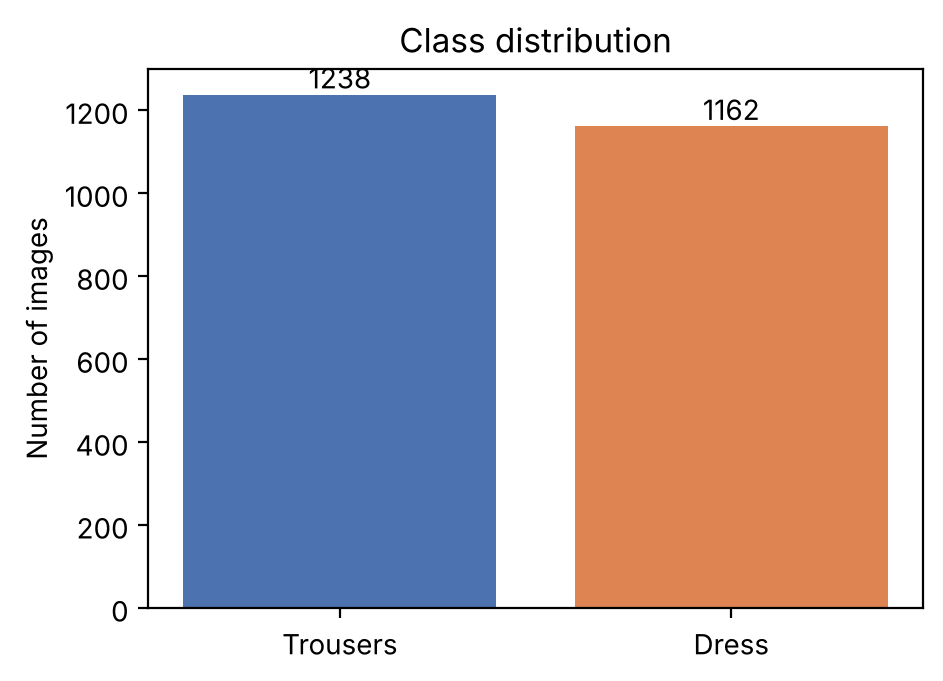

In [3]:
counts = df["label"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(CLASS_NAMES, counts.values, color=["#4c72b0", "#dd8452"])
for i, n in enumerate(counts.values):
    ax.text(i, n + 15, str(n), ha="center")
ax.set_ylabel("Number of images")
ax.set_title("Class distribution")
plt.show()

The classes are close to balanced (1,238 trousers vs. 1,162 dresses), so accuracy is a fair main metric and no resampling is needed.

### Sample images

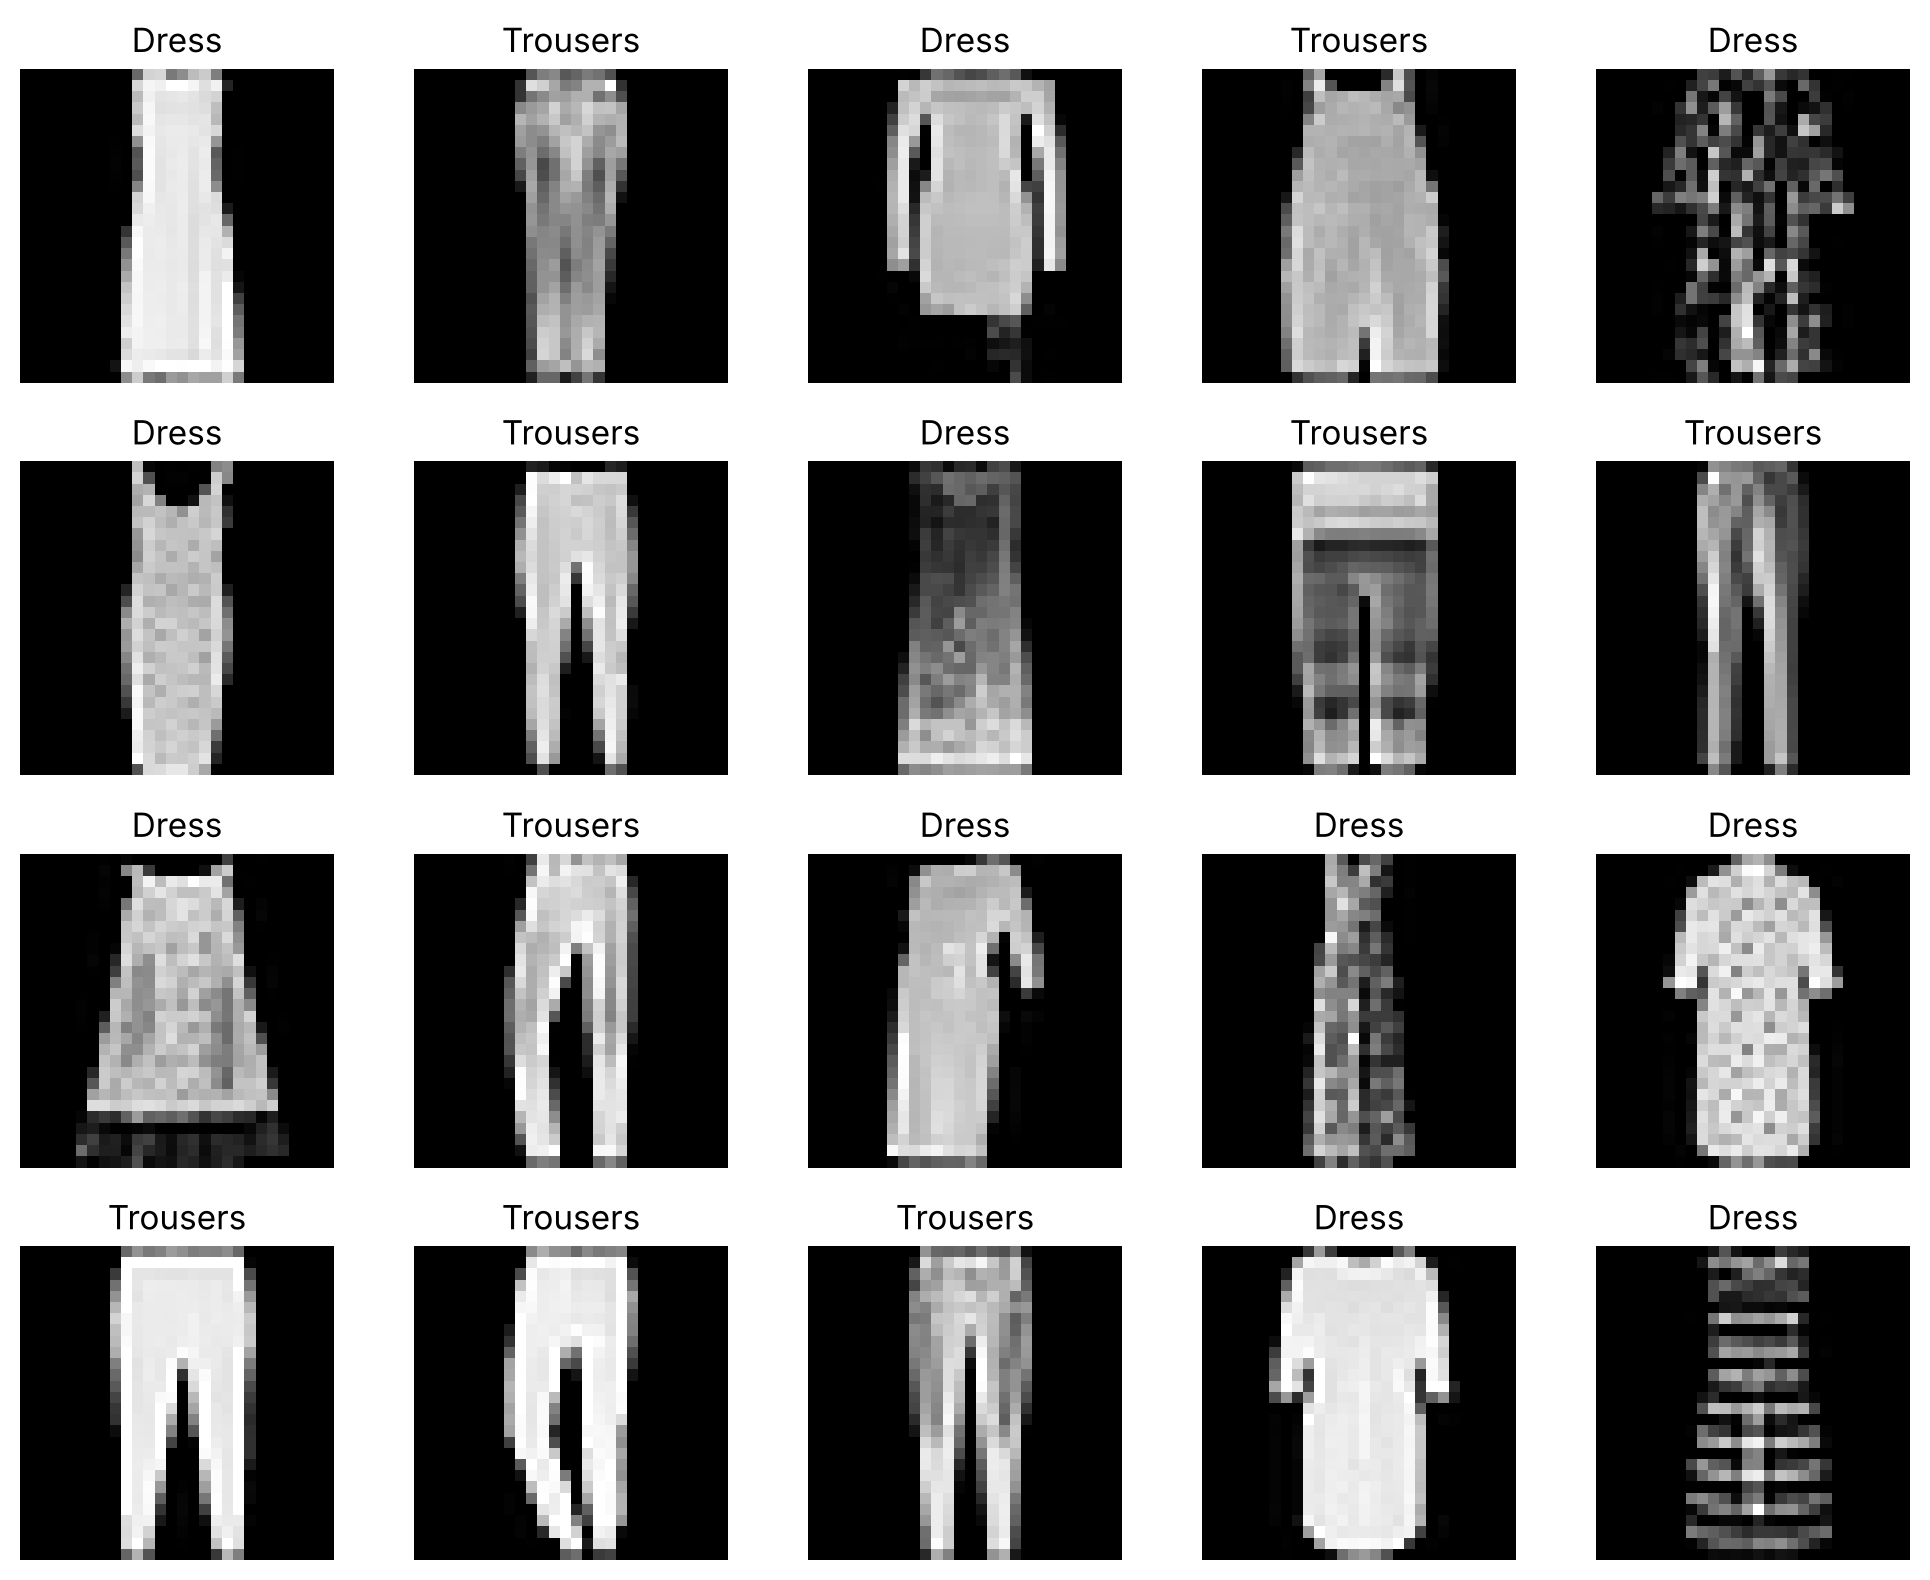

In [4]:
def plot_images(images, labels, rows=4, cols=5):
    """Show the first rows*cols images with their class names."""
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2))
    for ax, image, label in zip(axes.flat, images, labels):
        ax.imshow(image.reshape(28, 28), cmap="gray")
        ax.set_title(CLASS_NAMES[label])
        ax.axis("off")
    plt.tight_layout()
    plt.show()


X = df.drop(columns="label")
y = df["label"]

plot_images(X.values[:20], y.values[:20])

Trousers have a clear gap between the legs, while dresses are one solid shape that widens towards the bottom. This difference in overall shape suggests that even simple models, and a small number of features, could separate the classes well.

## 3. Evaluation setup

The labelled data is split into training (60%, 1,440 images), validation (20%, 480) and test (20%, 480) sets with a fixed random seed. Models are trained on the training set and compared on the validation set. The test set is used only once, to evaluate the final model. The two classes are nearly balanced, so accuracy is the main comparison metric. The final model is also checked with precision, recall and F1.

In [5]:
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.4, random_state=RANDOM_SEED)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, random_state=RANDOM_SEED)

for name, part in [("Train", X_train), ("Validation", X_val), ("Test", X_test)]:
    print(f"{name:<11} {part.shape}")

Train       (1440, 784)
Validation  (480, 784)
Test        (480, 784)


### Helper functions

All experiments follow the same pattern: fit on the training set, score on the validation set. The helpers below avoid repeating that code.

- `scale` fits a preprocessing method on the training set only and applies it to all three sets, so no information leaks from validation or test data.
- `val_accuracy` trains one model and returns its validation accuracy.
- `tune` runs a grid search on the validation set. When a dimensionality reduction method is given, it is fitted once per setting (e.g. per number of components) and reused for every classifier setting, which saves a lot of computation.
- `record` stores each result for the summary table in section 8.

In [6]:
def scale(scaler, *datasets):
    """Fit `scaler` on the first dataset (training set) and transform all of them."""
    scaler.fit(datasets[0])
    return [scaler.transform(d) for d in datasets]


def val_accuracy(model, X_tr, X_v):
    """Train `model` and return its accuracy on the validation set."""
    model.fit(X_tr, y_train)
    return accuracy_score(y_val, model.predict(X_v))


def tune(make_model, param_grid, X_tr, X_v, make_reducer=None, reducer_keys=("n_components", "n_neighbors")):
    """Grid search on the validation set.

    make_model(**params) builds the classifier. If make_reducer is given, the parameters
    named in reducer_keys go to make_reducer and the rest to make_model. Each reducer
    setting is fitted once on the training set and cached.

    Returns a DataFrame with one row per setting, sorted by validation accuracy.
    """
    cache, rows = {}, []
    for params in ParameterGrid(param_grid):
        model_params = {k: v for k, v in params.items() if k not in reducer_keys}
        if make_reducer is None:
            Xr_tr, Xr_v = X_tr, X_v
        else:
            reducer_params = {k: v for k, v in params.items() if k in reducer_keys}
            key = tuple(sorted(reducer_params.items()))
            if key not in cache:
                reducer = make_reducer(**reducer_params).fit(X_tr)
                cache[key] = (reducer.transform(X_tr), reducer.transform(X_v))
            Xr_tr, Xr_v = cache[key]
        rows.append({**params, "val_accuracy": val_accuracy(make_model(**model_params), Xr_tr, Xr_v)})

    results = pd.DataFrame(rows)
    # Stable sort keeps the first best setting on ties
    return results.sort_values("val_accuracy", ascending=False, kind="stable").reset_index(drop=True)


summary = []

def record(model, preprocessing, reduction, tuned, accuracy):
    summary.append({"Model": model, "Preprocessing": preprocessing, "Reduction": reduction,
                    "Tuned": tuned, "Val accuracy": accuracy})


def best(results):
    """Print the best setting and the top 5 settings of a grid search."""
    top = results.iloc[:1].to_dict("records")[0]
    top = {k: (v.item() if hasattr(v, "item") else v) for k, v in top.items()}
    accuracy = top.pop("val_accuracy")
    print(f"Best validation accuracy: {accuracy:.4f} with {top}")
    display(results.head(5))
    return top, accuracy

## 4. Baseline models

Each model is first trained on raw pixel values with default settings.

- **SVM** (linear and RBF kernel) handles high-dimensional data well, because its decision depends only on the support vectors, not on every feature separately.
- **Naive Bayes** is very fast to train. It assumes that features are independent given the class, which is not true for neighbouring pixels. Three variants are tested: Gaussian (continuous features), multinomial (counts) and Bernoulli (binary features).
- **LDA** finds the linear projection that best separates the two classes.

In [7]:
baselines = {
    "SVM (linear)": SVC(kernel="linear", C=1),
    "SVM (RBF)": SVC(kernel="rbf", C=1, gamma="scale"),
    "Gaussian NB": GaussianNB(),
    "Multinomial NB": MultinomialNB(),
    "Bernoulli NB": BernoulliNB(),
    "LDA": LinearDiscriminantAnalysis(),
}

for name, model in baselines.items():
    acc = val_accuracy(model, X_train, X_val)
    record(name, "none", "none", "no", acc)
    print(f"{name:<15} {acc:.4f}")

SVM (linear)    0.9583


SVM (RBF)       0.9708
Gaussian NB     0.9500


Multinomial NB  0.9437
Bernoulli NB    0.9333


LDA             0.9146


On raw pixels, the RBF SVM is the strongest baseline. LDA is the weakest, likely because it must estimate a 784 × 784 covariance matrix from only 1,440 images.

## 5. Effect of preprocessing

Four preprocessing methods are compared:
- **Min-max scaling:** each pixel scaled to the range 0–1.
- **Robust scaling:** centred on the median and scaled by the interquartile range.
- **Standardisation:** each pixel scaled to mean 0 and standard deviation 1.
- **Binarisation:** each pixel set to 1 if it is non-zero, otherwise 0 (Gaussian NB only).

All of them are fitted on the training set only.

In [8]:
X_train_minmax, X_val_minmax, X_test_minmax = scale(MinMaxScaler(), X_train, X_val, X_test)
X_train_robust, X_val_robust, X_test_robust = scale(RobustScaler(), X_train, X_val, X_test)
X_train_std, X_val_std, X_test_std = scale(StandardScaler(), X_train, X_val, X_test)
X_train_bin, X_val_bin, X_test_bin = scale(Binarizer(), X_train, X_val, X_test)

scaled = {
    "min-max": (X_train_minmax, X_val_minmax),
    "robust": (X_train_robust, X_val_robust),
    "standard": (X_train_std, X_val_std),
    "binarised": (X_train_bin, X_val_bin),
}

### SVM

In [9]:
for prep in ["min-max", "robust", "standard"]:
    for name, model in [("SVM (linear)", SVC(kernel="linear", C=1)), ("SVM (RBF)", SVC(kernel="rbf", C=1, gamma="scale"))]:
        acc = val_accuracy(model, *scaled[prep])
        record(name, prep, "none", "no", acc)
        print(f"{name:<13} {prep:<9} {acc:.4f}")

SVM (linear)  min-max   0.9792
SVM (RBF)     min-max   0.9688


SVM (linear)  robust    0.9292


SVM (RBF)     robust    0.8083
SVM (linear)  standard  0.9625


SVM (RBF)     standard  0.9646


Min-max scaling gives the best result for the linear SVM (97.92%). Robust scaling hurts both SVMs, the RBF SVM most of all (80.83%).

### Naive Bayes

Only Gaussian NB is sensitive to the scale of the features. Multinomial and Bernoulli NB are also tested with min-max scaling for comparison.

In [10]:
for name, model in [("Gaussian NB", GaussianNB()), ("Multinomial NB", MultinomialNB()), ("Bernoulli NB", BernoulliNB())]:
    acc = val_accuracy(model, *scaled["min-max"])
    record(name, "min-max", "none", "no", acc)
    print(f"{name:<15} min-max   {acc:.4f}")

for prep in ["robust", "standard", "binarised"]:
    acc = val_accuracy(GaussianNB(), *scaled[prep])
    record("Gaussian NB", prep, "none", "no", acc)
    print(f"{'Gaussian NB':<15} {prep:<9} {acc:.4f}")

Gaussian NB     min-max   0.9354
Multinomial NB  min-max   0.9437
Bernoulli NB    min-max   0.9333
Gaussian NB     robust    0.9542
Gaussian NB     standard  0.9062
Gaussian NB     binarised 0.9542


Min-max scaling does not change Multinomial and Bernoulli NB. For Gaussian NB, binarisation works best, together with robust scaling: whether a pixel is covered at all says more about the shape than its exact brightness.

### LDA

In [11]:
for prep in ["min-max", "robust", "standard"]:
    acc = val_accuracy(LinearDiscriminantAnalysis(), *scaled[prep])
    record("LDA", prep, "none", "no", acc)
    print(f"LDA  {prep:<9} {acc:.4f}")

LDA  min-max   0.9146


LDA  robust    0.9146


LDA  standard  0.9146


Scaling has no effect on LDA, as expected: LDA is invariant to rescaling each feature, because it accounts for feature variances in its covariance estimate.

## 6. Hyperparameter tuning

Each model is tuned with a grid search on the validation set, using the preprocessing that worked best for it in section 5.

### SVM (min-max scaling)

Parameters: regularisation strength `C`, kernel coefficient `gamma`, and kernel type.

In [12]:
svm_results = tune(SVC, {"C": range(1, 50), "gamma": ["scale", "auto"], "kernel": ["rbf", "linear"]},
                   X_train_minmax, X_val_minmax)
_, acc = best(svm_results)
record("SVM", "min-max", "none", "yes", acc)

Best validation accuracy: 0.9875 with {'C': 6, 'gamma': 'scale', 'kernel': 'rbf'}


,C,gamma,kernel,val_accuracy
0,6,scale,rbf,0.987500
1,7,scale,rbf,0.985417
2,8,scale,rbf,0.985417
3,9,scale,rbf,0.985417
4,10,scale,rbf,0.985417


### Gaussian NB (binarised)

Parameter: `var_smoothing`, a small value added to the variances for numerical stability.

In [13]:
gnb_results = tune(GaussianNB, {"var_smoothing": np.arange(1e-9, 1e-5, 1e-8)}, X_train_bin, X_val_bin)
_, acc = best(gnb_results)
record("Gaussian NB", "binarised", "none", "yes", acc)

Best validation accuracy: 0.9542 with {'var_smoothing': 1e-09}


,var_smoothing,val_accuracy
0,1.000000e-09,0.954167
1,1.100000e-08,0.950000
2,2.100000e-08,0.950000
3,3.100000e-08,0.950000
4,4.100000e-08,0.950000


The default value is already the best one, so tuning does not change the result.

### Multinomial NB (raw pixels)

Parameter: smoothing strength `alpha`.

In [14]:
mnb_results = tune(MultinomialNB, {"alpha": np.arange(0.0001, 10, 0.01)}, X_train, X_val)
_, acc = best(mnb_results)
record("Multinomial NB", "none", "none", "yes", acc)

Best validation accuracy: 0.9437 with {'alpha': 0.0001}


,alpha,val_accuracy
0,0.0001,0.94375
1,0.0101,0.94375
2,0.0201,0.94375
3,0.0301,0.94375
4,0.0401,0.94375


Tuning `alpha` does not improve on the default model.

### Bernoulli NB (raw pixels)

Parameters: smoothing strength `alpha` and `binarize`, the threshold above which a pixel counts as 1.

In [15]:
bnb_results = tune(BernoulliNB, {"alpha": np.arange(0.01, 3, 0.5), "binarize": np.arange(0.01, 3, 0.1)},
                   X_train, X_val)
_, acc = best(bnb_results)
record("Bernoulli NB", "none", "none", "yes", acc)

Best validation accuracy: 0.9396 with {'alpha': 0.01, 'binarize': 2.01}


,alpha,binarize,val_accuracy
0,0.01,2.01,0.939583
1,0.01,2.11,0.939583
2,0.01,2.21,0.939583
3,0.01,2.31,0.939583
4,0.01,2.41,0.939583


### LDA (raw pixels)

Parameters: `solver` and `shrinkage`. Shrinkage pulls the estimated covariance matrix towards a simpler diagonal form, which helps when there are many features compared with the number of samples, as here (784 features, 1,440 images).

In [16]:
lda_results = tune(LinearDiscriminantAnalysis,
                   {"solver": ["lsqr", "eigen"], "shrinkage": np.arange(0.01, 1, 0.01)},
                   X_train, X_val)
_, acc = best(lda_results)
record("LDA", "none", "none", "yes", acc)

Best validation accuracy: 0.9792 with {'shrinkage': 0.19, 'solver': 'lsqr'}


,shrinkage,solver,val_accuracy
0,0.19,lsqr,0.979167
1,0.19,eigen,0.979167
2,0.20,lsqr,0.979167
3,0.20,eigen,0.979167
4,0.21,lsqr,0.979167


Shrinkage makes a large difference for LDA: validation accuracy rises from about 91% to almost 98%, confirming that the unregularised covariance estimate was the problem.

## 7. Dimensionality reduction

Two methods are tested, each combined with every classifier. The number of components (and, for LLE, the number of neighbours) is tuned together with the classifier's own parameters.

- **PCA (principal component analysis)** projects the data onto the directions with the largest variance. It is linear and fast.
- **LLE (locally linear embedding)** is a non-linear method. It describes each image as a combination of its nearest neighbours and looks for a low-dimensional representation that keeps those relationships.

**Multinomial NB is not tested here:** it requires non-negative features, and both PCA and LLE produce negative values.

### PCA

In [17]:
make_pca = lambda n_components: PCA(n_components=n_components, random_state=RANDOM_SEED)

#### SVM + PCA (min-max scaling)

In [18]:
svm_pca_results = tune(SVC, {"n_components": range(10, 15), "C": range(1, 10),
                             "gamma": ["scale", "auto"], "kernel": ["rbf", "linear"]},
                       X_train_minmax, X_val_minmax, make_reducer=make_pca)
svm_pca_params, acc = best(svm_pca_results)
record("SVM", "min-max", "PCA", "yes", acc)

Best validation accuracy: 0.9896 with {'C': 4, 'gamma': 'auto', 'kernel': 'rbf', 'n_components': 11}


,C,gamma,kernel,n_components,val_accuracy
0,4,auto,rbf,11,0.989583
1,4,auto,rbf,12,0.987500
2,4,auto,rbf,14,0.987500
3,5,auto,rbf,11,0.987500
4,5,auto,rbf,12,0.987500


PCA slightly improves the SVM: with only 11 components it reaches 98.96%, higher than the tuned SVM on all 784 pixels.

#### Gaussian NB + PCA (binarised)

In [19]:
gnb_pca_results = tune(GaussianNB, {"n_components": range(1, 20), "var_smoothing": np.arange(1e-9, 1e-7, 1e-8)},
                       X_train_bin, X_val_bin, make_reducer=make_pca)
_, acc = best(gnb_pca_results)
record("Gaussian NB", "binarised", "PCA", "yes", acc)

Best validation accuracy: 0.9563 with {'n_components': 18, 'var_smoothing': 1e-09}


,n_components,var_smoothing,val_accuracy
0,18,1.000000e-09,0.95625
1,18,1.100000e-08,0.95625
2,18,2.100000e-08,0.95625
3,18,3.100000e-08,0.95625
4,18,4.100000e-08,0.95625


PCA improves Gaussian NB slightly. Principal components are uncorrelated, which fits the independence assumption of naive Bayes better than raw pixels do.

#### Bernoulli NB + PCA (binarised)

In [20]:
bnb_pca_results = tune(BernoulliNB, {"n_components": range(15, 20), "alpha": np.arange(0.01, 1, 0.5),
                                     "binarize": np.arange(0.01, 1.5, 0.1)},
                       X_train_bin, X_val_bin, make_reducer=make_pca)
_, acc = best(bnb_pca_results)
record("Bernoulli NB", "binarised", "PCA", "yes", acc)

Best validation accuracy: 0.8917 with {'alpha': 0.01, 'binarize': 0.01, 'n_components': 16}


,alpha,binarize,n_components,val_accuracy
0,0.01,0.01,16,0.891667
1,0.51,0.01,16,0.891667
2,0.01,0.01,15,0.889583
3,0.01,0.01,17,0.889583
4,0.01,0.01,19,0.889583


PCA lowers the accuracy of Bernoulli NB: the model binarises its inputs again, and thresholding continuous principal components loses information.

#### LDA + PCA (min-max scaling)

In [21]:
lda_pca_results = tune(LinearDiscriminantAnalysis, {"n_components": range(10, 15), "solver": ["lsqr", "eigen"],
                                                    "shrinkage": np.arange(0.01, 1, 0.01)},
                       X_train_minmax, X_val_minmax, make_reducer=make_pca)
_, acc = best(lda_pca_results)
record("LDA", "min-max", "PCA", "yes", acc)

Best validation accuracy: 0.9750 with {'n_components': 13, 'shrinkage': 0.01, 'solver': 'lsqr'}


,n_components,shrinkage,solver,val_accuracy
0,13,0.01,lsqr,0.975
1,13,0.01,eigen,0.975
2,13,0.02,lsqr,0.975
3,13,0.02,eigen,0.975
4,13,0.03,lsqr,0.975


PCA slightly lowers LDA's accuracy compared with tuned LDA on all pixels.

### LLE

LLE is much slower than PCA, so the parameter ranges are kept small.

In [22]:
make_lle = lambda n_components, n_neighbors: LocallyLinearEmbedding(
    n_components=n_components, n_neighbors=n_neighbors, random_state=RANDOM_SEED)

#### SVM + LLE (min-max scaling)

In [23]:
svm_lle_results = tune(SVC, {"n_components": range(10, 15), "n_neighbors": range(10, 12), "C": range(1, 10),
                             "gamma": ["scale", "auto"], "kernel": ["rbf", "linear"]},
                       X_train_minmax, X_val_minmax, make_reducer=make_lle)
_, acc = best(svm_lle_results)
record("SVM", "min-max", "LLE", "yes", acc)

Best validation accuracy: 0.9667 with {'C': 6, 'gamma': 'scale', 'kernel': 'rbf', 'n_components': 12, 'n_neighbors': 10}


,C,gamma,kernel,n_components,n_neighbors,val_accuracy
0,6,scale,rbf,12,10,0.966667
1,2,scale,rbf,12,10,0.964583
2,2,scale,rbf,13,10,0.964583
3,3,scale,rbf,12,10,0.964583
4,3,scale,rbf,13,10,0.964583


#### Gaussian NB + LLE (binarised)

In [24]:
gnb_lle_results = tune(GaussianNB, {"n_components": range(15, 20), "n_neighbors": range(10, 12),
                                    "var_smoothing": np.arange(1e-9, 1e-7, 1e-8)},
                       X_train_bin, X_val_bin, make_reducer=make_lle)
_, acc = best(gnb_lle_results)
record("Gaussian NB", "binarised", "LLE", "yes", acc)

Best validation accuracy: 0.9458 with {'n_components': 15, 'n_neighbors': 11, 'var_smoothing': 1e-09}


,n_components,n_neighbors,var_smoothing,val_accuracy
0,15,11,1.000000e-09,0.945833
1,15,11,1.100000e-08,0.945833
2,15,11,2.100000e-08,0.945833
3,15,11,3.100000e-08,0.945833
4,15,11,4.100000e-08,0.945833


#### Bernoulli NB + LLE (binarised)

In [25]:
bnb_lle_results = tune(BernoulliNB, {"n_components": range(15, 20), "n_neighbors": range(10, 12),
                                     "alpha": np.arange(0.01, 1, 0.5), "binarize": np.arange(0.01, 1, 0.5)},
                       X_train_bin, X_val_bin, make_reducer=make_lle)
_, acc = best(bnb_lle_results)
record("Bernoulli NB", "binarised", "LLE", "yes", acc)

Best validation accuracy: 0.9104 with {'alpha': 0.01, 'binarize': 0.01, 'n_components': 15, 'n_neighbors': 10}


,alpha,binarize,n_components,n_neighbors,val_accuracy
0,0.01,0.01,15,10,0.910417
1,0.51,0.01,15,10,0.910417
2,0.01,0.01,16,10,0.908333
3,0.01,0.01,18,10,0.908333
4,0.01,0.01,19,10,0.908333


#### LDA + LLE (binarised)

In [26]:
lda_lle_results = tune(LinearDiscriminantAnalysis, {"n_components": range(10, 15), "n_neighbors": range(10, 12),
                                                    "solver": ["lsqr", "eigen"], "shrinkage": np.arange(0.01, 1, 0.01)},
                       X_train_bin, X_val_bin, make_reducer=make_lle)
_, acc = best(lda_lle_results)
record("LDA", "binarised", "LLE", "yes", acc)

Best validation accuracy: 0.9521 with {'n_components': 14, 'n_neighbors': 10, 'shrinkage': 0.51, 'solver': 'lsqr'}


,n_components,n_neighbors,shrinkage,solver,val_accuracy
0,14,10,0.51,lsqr,0.952083
1,14,10,0.51,eigen,0.952083
2,14,10,0.52,lsqr,0.952083
3,14,10,0.52,eigen,0.952083
4,14,10,0.53,lsqr,0.952083


LLE lowers accuracy for every model compared with using all pixels, and for every model except Bernoulli NB it is also worse than PCA. A wider search over `n_neighbors` and `n_components` might help, but it was not explored here because of computation time.

## 8. Results summary

All validation results from sections 4–7 in one table, best first.

In [27]:
summary_df = (pd.DataFrame(summary)
              .sort_values("Val accuracy", ascending=False, kind="stable")
              .reset_index(drop=True))
summary_df.style.format({"Val accuracy": "{:.2%}"}).hide(axis="index")

Model,Preprocessing,Reduction,Tuned,Val accuracy
SVM,min-max,PCA,yes,98.96%
SVM,min-max,none,yes,98.75%
SVM (linear),min-max,none,no,97.92%
LDA,none,none,yes,97.92%
LDA,min-max,PCA,yes,97.50%
SVM (RBF),none,none,no,97.08%
SVM (RBF),min-max,none,no,96.88%
SVM,min-max,LLE,yes,96.67%
SVM (RBF),standard,none,no,96.46%
SVM (linear),standard,none,no,96.25%


Best validation accuracy per model family and feature space:

In [28]:
best_tuned = (pd.DataFrame(summary)
              .query("Tuned == 'yes'")
              .pivot_table(index="Model", columns="Reduction", values="Val accuracy", aggfunc="max")
              .reindex(columns=["none", "PCA", "LLE"]))
best_tuned.columns = ["All pixels", "PCA", "LLE"]
best_tuned.style.format("{:.2%}", na_rep="–").highlight_max(axis=None, color="#cde3f5")

,All pixels,PCA,LLE
Model,,,
Bernoulli NB,93.96%,89.17%,91.04%
Gaussian NB,95.42%,95.62%,94.58%
LDA,97.92%,97.50%,95.21%
Multinomial NB,94.38%,–,–
SVM,98.75%,98.96%,96.67%


## 9. Final model on the test set

The final model is the SVM with min-max scaling and PCA, which had the highest validation accuracy. It is built as a scikit-learn `Pipeline`, so the same scaling and PCA steps are applied automatically to any new data. It is trained on the training set and evaluated once on the untouched test set.

In [29]:
final_model = Pipeline([
    ("scale", MinMaxScaler()),
    ("pca", PCA(n_components=svm_pca_params["n_components"], random_state=RANDOM_SEED)),
    ("svm", SVC(C=svm_pca_params["C"], gamma=svm_pca_params["gamma"], kernel=svm_pca_params["kernel"])),
])
final_model.fit(X_train, y_train)

print(f"Validation accuracy: {accuracy_score(y_val, final_model.predict(X_val)):.4f}")
y_pred = final_model.predict(X_test)
print(f"Test accuracy:       {accuracy_score(y_test, y_pred):.4f}")

Validation accuracy: 0.9896
Test accuracy:       0.9688


              precision    recall  f1-score   support

    Trousers     0.9781    0.9571    0.9675       233
       Dress     0.9603    0.9798    0.9699       247

    accuracy                         0.9688       480
   macro avg     0.9692    0.9684    0.9687       480
weighted avg     0.9689    0.9688    0.9687       480



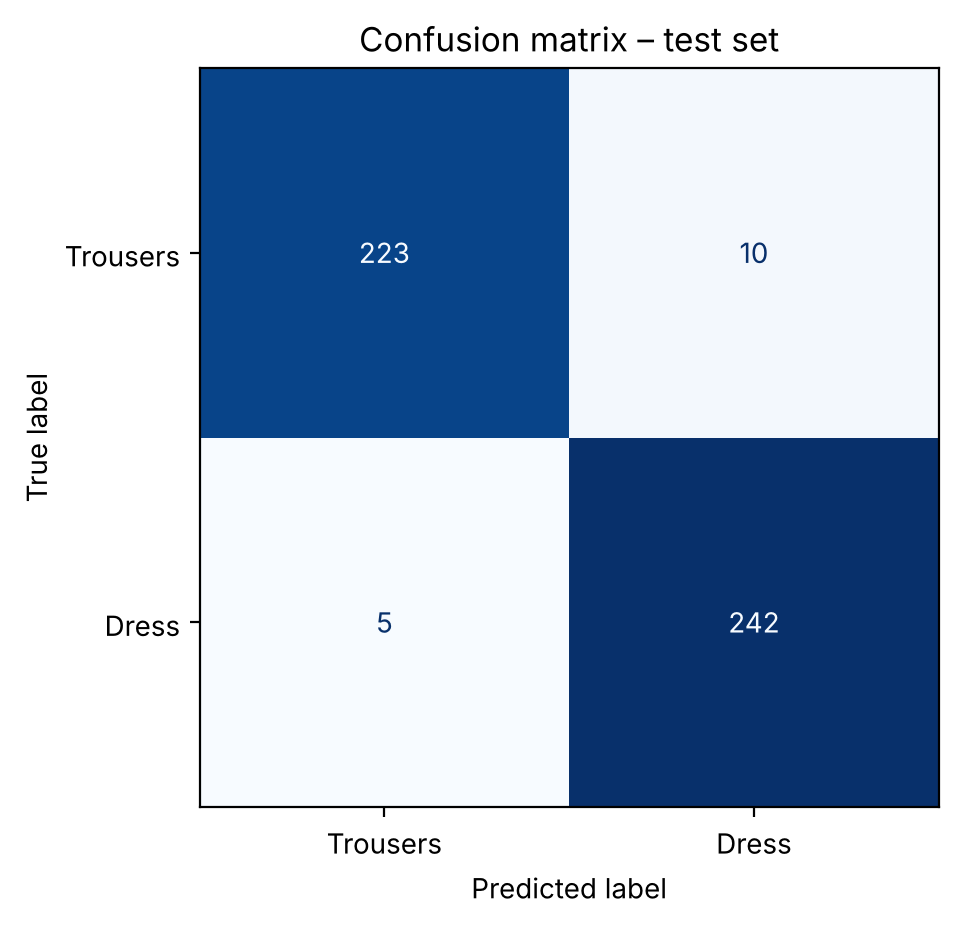

In [30]:
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=CLASS_NAMES).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix – test set")
plt.show()

The model makes 15 errors on 480 test images: 10 trousers predicted as dresses and 5 dresses predicted as trousers. Precision and recall are balanced across both classes (F1 0.968 for trousers, 0.970 for dresses).

## 10. Conclusions and limitations

**Findings**
- SVM was the strongest model family. Min-max scaling improved it, and PCA with 11 components gave a further small gain. A few principal components are enough to separate trousers from dresses.
- LDA came close after tuning shrinkage (97.9% validation). Naive Bayes models were weaker (best 95.6%), which fits their assumption that pixels are independent.
- LLE lowered accuracy for every model compared with using all pixels, and was worse than PCA for every model except Bernoulli NB (within the parameter range tested).
- MultinomialNB cannot be used after PCA or LLE, because both produce negative values.

**Limitations**
- Hundreds of configurations were ranked on a single validation set of 480 images. This makes the selection optimistic, which is visible in the gap between validation (98.96%) and test accuracy (96.88%). Cross-validation would give a more reliable estimate.
- The LLE parameter search was kept small because of computation time.
- The task uses only two of the ten Fashion-MNIST classes. The full 10-class problem is harder.
- Results for Bernoulli NB with PCA or LLE, and for LDA with LLE, can differ slightly between scikit-learn versions: the computed components can come out with flipped signs, and Bernoulli NB thresholds them. The final SVM model is not affected.

## 11. Predictions for unlabelled data

`evaluate.csv` contains images without labels. The final pipeline predicts a class for each of them, and the predictions are saved to `result.csv` together with each image's `ID`.

In [31]:
df_evaluate = pd.read_csv(DATA_DIR / "evaluate.csv")
print("Shape:", df_evaluate.shape)
print("Missing values:", df_evaluate.isnull().sum().sum())
df_evaluate.head()

Shape: (9600, 785)
Missing values: 0


,ID,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,61,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,0,0,0,...,109,121,76,0,0,0,0,0,0,0
3,3,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,3,0,...,198,195,206,0,0,0,0,0,0,0


In [32]:
ids = df_evaluate["ID"]
predictions = final_model.predict(df_evaluate.drop(columns="ID"))

df_result = pd.DataFrame({"ID": ids, "label": predictions})
df_result.to_csv("result.csv", index=False)

print(df_result["label"].map(dict(enumerate(CLASS_NAMES))).value_counts())

label
Dress       4979
Trousers    4621
Name: count, dtype: int64
